# Cross Correlation

In [329]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

In [330]:
angle = "45"
PathToFiles = f"../Audio_Files/HATS/H1/{angle}"

recordings = {}

# for folder in sorted(Path(PathToFiles).iterdir()):
#     if folder.is_dir():
#         recordings[folder.name] = {
#             'L': folder / "L.wav",
#             'R': folder / "R.wav"
#         }

dataL, fs = sf.read(f'{PathToFiles}/L.wav')
dataR, fs = sf.read(f'{PathToFiles}/R.wav')

recordings.update({'L': dataL, 'R': dataR})

In [331]:
r = 0.0875 

def woodworth_itd(angle_deg, r=r, c=343.0):
    theta = np.radians(angle_deg)
    if abs(theta) <= np.pi/2:
        return (r / c) * (np.sin(theta) + theta)
    else:
        return (r / c) * (np.sign(theta) * np.pi - theta + np.sin(theta))

def itd_to_angle(itd_s, r=r, c=343.0):
    max_itd = ((r / c) * (np.pi / 2 + 1) * fs * 1.5)
    itd_s = np.clip(itd_s, -max_itd, max_itd)
    f = lambda theta: (r/c) * (np.sin(theta) + theta) - itd_s
    try:
        return np.degrees(brentq(f, -np.pi/2 + 1e-6, np.pi/2 - 1e-6))
    except ValueError:
        return np.sign(itd_s) * 90.0

### Cross Correlation in the Frequency Domain

In [332]:
def fft_cross_correlation(x, y):
    X = fft(x)
    Y = fft(y)
    corr = ifft(X * np.conj(Y))
    return np.fft.fftshift(np.real(corr))

## TDOA processing

In [333]:
d = 0.21
c = 343
results = {}

    
L_click_idx = np.argmax(np.abs(dataL))
R_click_idx = np.argmax(np.abs(dataR))
    
click_offset = R_click_idx - L_click_idx 

L_Trimmed = dataL[L_click_idx + int(fs*2):]
R_Trimmed = dataR[R_click_idx + int(fs*2):]

min_len = min(len(L_Trimmed), len(R_Trimmed))
L_Trimmed = L_Trimmed[:min_len]
R_Trimmed = R_Trimmed[:min_len]

##### Pick Function here
correlation = fft_cross_correlation(L_Trimmed, R_Trimmed)

n = len(L_Trimmed)
lags = np.arange(-n//2, n//2)
lags = lags[:len(correlation)]

max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs

angle_deg = itd_to_angle(itd_seconds)

itd_expected = woodworth_itd(float(angle))
    
print(f"Calculated -> ITD={itd_seconds*1000:.3f}ms → {angle_deg:.1f}°")

print(f"Expected -> ITD={itd_expected*1000:.3f}ms → {angle}°")

print(f"L_click_idx: {L_click_idx} ({L_click_idx/fs:.2f}s)")
print(f"R_click_idx: {R_click_idx} ({R_click_idx/fs:.2f}s)")
print(f"click_offset: {click_offset} samples")
print(f"L_Trimmed start: {L_click_idx + int(fs)} ({(L_click_idx + int(fs))/fs:.2f}s)")
print(f"R_Trimmed start: {R_click_idx + int(fs)} ({(R_click_idx + int(fs))/fs:.2f}s)")
print(f"itd_samples raw: {np.argmax(correlation)}")
print(f"correlation at lag 0: {correlation[0]:.4f}")
print(f"correlation max: {np.max(correlation):.4f}")
print(f"Signal length: {len(L_Trimmed)}")
print(f"Expected ITD samples: {woodworth_itd(45)*fs:.2f}")
print(f"Measured ITD samples: {itd_samples}")

    
results = {f"{angle}": {'angle': angle_deg, 'itd': itd_seconds}}

Calculated -> ITD=0.500ms → 61.8°
Expected -> ITD=0.381ms → 45°
L_click_idx: 209134 (4.36s)
R_click_idx: 188747 (3.93s)
click_offset: -20387 samples
L_Trimmed start: 257134 (5.36s)
R_Trimmed start: 236747 (4.93s)
itd_samples raw: 481651
correlation at lag 0: 0.0034
correlation max: 0.5705
Signal length: 963253
Expected ITD samples: 18.28
Measured ITD samples: 24


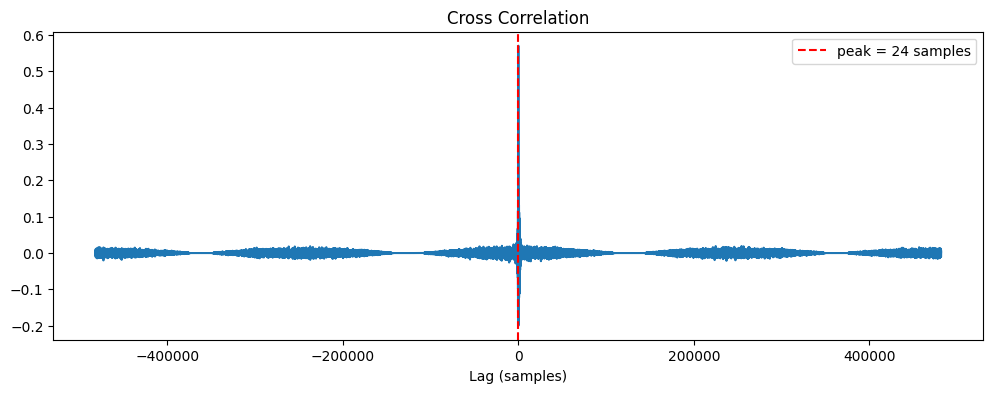

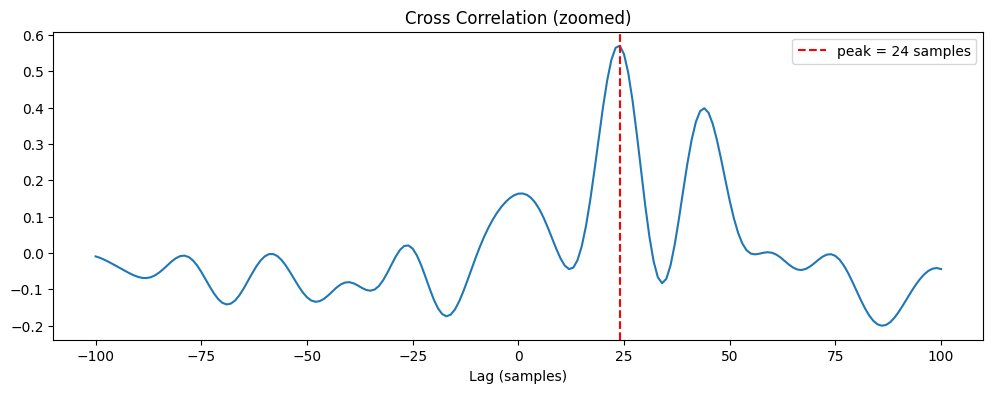

In [334]:
plt.figure(figsize=(12, 4))
plt.plot(lags, correlation)
plt.axvline(x=itd_samples, color='r', linestyle='--', label=f'peak = {itd_samples} samples')
plt.xlabel('Lag (samples)')
plt.title('Cross Correlation')
plt.legend()
plt.show()

zoom = 100  # samples either side
mask_zoom = (lags >= -zoom) & (lags <= zoom)
plt.figure(figsize=(12, 4))
plt.plot(lags[mask_zoom], correlation[mask_zoom])
plt.axvline(x=itd_samples, color='r', linestyle='--', label=f'peak = {itd_samples} samples')
plt.xlabel('Lag (samples)')
plt.title('Cross Correlation (zoomed)')
plt.legend()
plt.show()

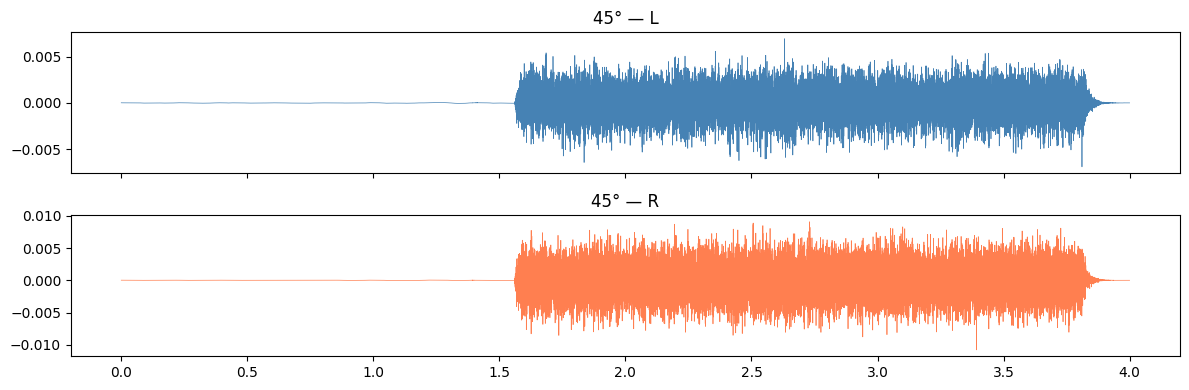

In [335]:
samples = int(fs*8)
t = np.arange(samples - (4*fs))/fs

fig, (axL, axR) = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
axL.plot(t, L_Trimmed[(4*fs):samples], linewidth=0.5, color='steelblue')
axR.plot(t, R_Trimmed[(4*fs):samples], linewidth=0.5, color='coral')
axL.set_title(f'{angle}° — L')
axR.set_title(f'{angle}° — R')
plt.tight_layout()
plt.show()


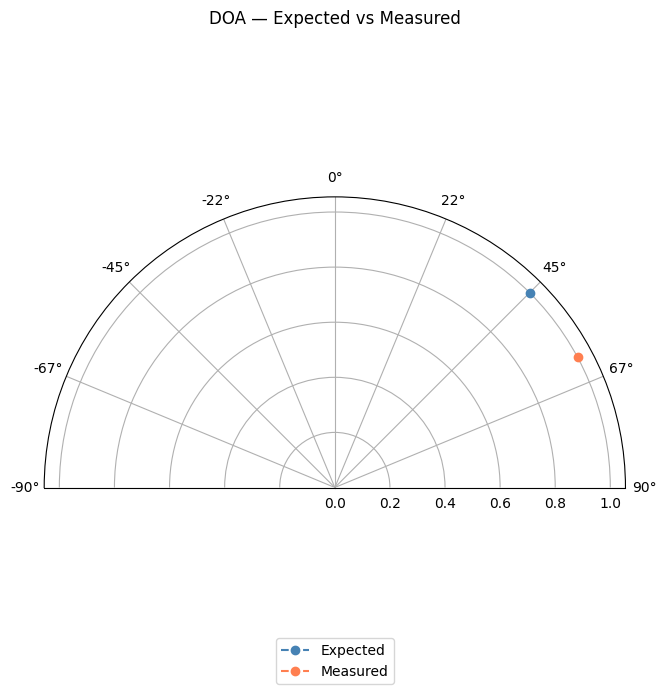

In [336]:
expected = sorted([float(k) for k in results.keys()])
measured = [results[str(e if e != int(e) else int(e))]['angle'] for e in expected]

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(7, 7))

# Convert to radians, offset by 90° so 0° is at top
expected_rad = -np.radians(expected) + np.pi/2
measured_rad = -np.radians(measured) + np.pi/2

ax.plot(expected_rad, np.ones(len(expected_rad)), 'o--', color='steelblue', label='Expected')
ax.plot(measured_rad, np.ones(len(measured_rad)), 'o--', color='coral', label='Measured')

# Restrict to upper semicircle
ax.set_thetamin(0)
ax.set_thetamax(180)

# Label as degrees from -90 to 90
ax.set_thetagrids(np.arange(0, 181, 22.5),
                  labels=[f'{int(a)}°' for a in np.arange(90, -91, -22.5)])

ax.set_title('DOA — Expected vs Measured', pad=20)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()